# CB 03 Interpolasi Sinyal RSSI
## Polinomial Lagrange dan Natural Cubic Spline

**Kelompok:** Fiona Evelyn Wijaya Silaban (255150201111022), Imam Hannani (255150201111020), M Kaka Chadafi F (255150201111018).

Di notebook ini, kita memakai data UJIIndoorLoc untuk memperkirakan kekuatan sinyal Wi-Fi di antara lokasi yang sudah diukur. Hasil Lagrange dan spline kemudian dibandingkan dengan pengukuran yang disisihkan untuk pengujian.

Kita juga membuat peta kekuatan sinyal dan mencoba fungsi contoh untuk melihat kenapa kurva Lagrange kadang bergelombang berlebihan saat titik acuannya ditambah.

Data Wi-Fi ini dipakai sebagai contoh pemetaan sinyal untuk jaringan IoT. Pengukurannya berasal dari dataset, bukan dari sensor yang dipasang kelompok.

Beberapa istilah yang akan muncul: **simpul** adalah titik acuan interpolasi, **galat** adalah selisih hasil perkiraan dengan nilai pembanding, dan **penampang** adalah jalur sempit pada peta yang kita perlakukan sebagai satu garis.

## 1. Persiapan dan cara menjalankan
Gunakan Python 3.10 atau lebih baru. Ekstrak paket ZIP, buka notebook di folder `CB03`, lalu **Run All**. Pustaka yang dipakai adalah `numpy`, `pandas`, `scipy`, dan `matplotlib`. Kalau belum terpasang, jalankan `%pip install numpy pandas scipy matplotlib` pada cell baru.

Dataset sudah disertakan dalam `data/ujiindoorloc.zip`. Kalau file itu tidak ditemukan, program akan mengunduhnya dari UCI. Dataset yang sama juga ada di Kaggle, tetapi kita tidak perlu token Kaggle untuk menjalankan notebook ini. Hasil tabel dan gambar disimpan ke `hasil/`.

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import urllib.request
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, BarycentricInterpolator, CloughTocher2DInterpolator, LinearNDInterpolator

DATA = Path("data")
OUT = Path("hasil")
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True})
np.set_printoptions(precision=6, suppress=True)
print("Python", platform.python_version())
print("NumPy", np.__version__, "pandas", pd.__version__, "SciPy", scipy.__version__)

Python 3.12.14
NumPy 2.3.5 pandas 2.2.3 SciPy 1.17.0


## 2. Membaca data nyata
Sumber: [Kaggle](https://www.kaggle.com/datasets/giantuji/UjiIndoorLoc) dan [UCI](https://archive.ics.uci.edu/dataset/310/ujiindoorloc), DOI `10.24432/C5MS59`, lisensi CC BY 4.0.

Hanya `trainingData.csv` yang digunakan sebagai kumpulan pengukuran. `validationData.csv` asli tidak dipakai, karena eksperimen ini menahan lokasi dari penampang yang sama, bukan menguji model lokalisasi lintas perangkat/waktu.

`WAP001` sampai `WAP520` adalah RSSI access point. **100 berarti tidak terdeteksi**, bukan sinyal sangat kuat. Nilai tersebut dijadikan `NaN`, bukan diganti angka RSSI buatan. `LONGITUDE` dan `LATITUDE` pada dataset ini merupakan koordinat proyeksi, bukan sudut derajat. Grafik memakai selisih koordinat proyeksi. Jaraknya tidak diklaim sebagai jarak fisik presisi dari gateway.

In [2]:
url = "https://archive.ics.uci.edu/static/public/310/ujiindoorloc.zip"
archive = DATA / "ujiindoorloc.zip"
local_csv = DATA / "trainingData.csv"
if local_csv.exists():
    raw = pd.read_csv(local_csv)
    source_hash = hashlib.sha256(local_csv.read_bytes()).hexdigest()
else:
    if not archive.exists():
        with urllib.request.urlopen(url, timeout=120) as response:
            archive.write_bytes(response.read())
    source_hash = hashlib.sha256(archive.read_bytes()).hexdigest()
    with ZipFile(archive) as z:
        name = next(n for n in z.namelist() if n.endswith("trainingData.csv"))
        raw = pd.read_csv(BytesIO(z.read(name)))
wap_cols = sorted(c for c in raw if c.startswith("WAP"))
assert len(wap_cols) == 520
print("Ukuran data:", raw.shape)
print("SHA256 sumber:", source_hash)
print(raw.groupby(["BUILDINGID", "FLOOR"]).size().to_string())

Ukuran data: (19937, 529)
SHA256 sumber: 893512b82dfd7a7c345d84195b1c8019fbca0fa0d7820ce491ce5aa45ec3782f
BUILDINGID  FLOOR
0           0        1059
            1        1356
            2        1443
            3        1391
1           0        1368
            1        1484
            2        1396
            3         948
2           0        1942
            1        2162
            2        1577
            3        2709
            4        1102


## 3. Menentukan penampang 1D dari posisi 2D
`CubicSpline` membutuhkan satu variabel bebas yang urut. Mengurutkan seluruh titik 2D berdasarkan longitude saja dapat mencampur posisi dari koridor berbeda.

Kita memilih jalurnya dengan langkah berikut, sebelum menghitung hasil pengujian:
1. Pilih gedung dan lantai dengan jumlah baris terbanyak.
2. Gabungkan pengukuran berulang di **koordinat yang sama** dengan median RSSI per AP.
3. Cari arah garis pada sudut 0–179 derajat dan pita selebar ±1 satuan proyeksi yang memuat koordinat terbanyak. Pada tahap ini, yang dilihat hanya posisi titiknya.
4. Proyeksikan titik pada arah garis menjadi $t$ dan jarak tegak lurus menjadi $q$. Kelompokkan titik bertetangga dengan celah $t$ tidak lebih dari 2 satuan. Dari setiap kelompok, pilih **satu koordinat asli** yang paling dekat dengan garis tengah, bukan membuat RSSI baru.
5. Pilih AP yang paling sering terdeteksi pada koordinat wakil. Kalau jumlahnya sama, pilih berdasarkan urutan nama AP. Buang lokasi tanpa deteksi AP itu.

Posisi satu dimensi $s=t-t_{min}$ menunjukkan letak sepanjang penampang, **bukan jarak ke pemancar**. Ini pendekatan penampang karena titik dapat berada sampai 1 satuan di sisi garis. Median menggabungkan variasi waktu/perangkat dan tidak menghilangkan seluruh variasi pembacaan alat.

In [3]:
counts = raw.groupby(["BUILDINGID", "FLOOR"]).size().sort_values(ascending=False)
building, floor = map(int, counts.index[0])
subset = raw[(raw.BUILDINGID == building) & (raw.FLOOR == floor)].copy()
subset[wap_cols] = subset[wap_cols].replace(100, np.nan)
locations = subset.groupby(["LONGITUDE", "LATITUDE"], sort=True)[wap_cols].median().reset_index()
xy = locations[["LONGITUDE", "LATITUDE"]].to_numpy()
origin = xy.mean(axis=0)
centered = xy - origin
best_count = -1
for angle in range(180):
    theta = np.deg2rad(angle)
    direction = np.array([np.cos(theta), np.sin(theta)])
    perpendicular = np.array([-direction[1], direction[0]])
    t = centered @ direction
    q = centered @ perpendicular
    for center in q:
        mask = np.abs(q - center) <= 1.0
        if mask.sum() > best_count:
            best_count = int(mask.sum())
            best = (angle, float(center), direction.copy(), perpendicular.copy(), t.copy(), q.copy(), mask.copy())
angle, center, direction, perpendicular, t, q, mask = best
strip = locations.loc[mask].copy()
strip["t"] = t[mask]
strip["offset"] = q[mask] - center
strip = strip.sort_values("t")
strip["cluster"] = (strip.t.diff().fillna(np.inf) > 2.0).cumsum()
indices = strip.offset.abs().groupby(strip.cluster).idxmin()
representatives = strip.loc[indices].sort_values("t")
coverage = representatives[wap_cols].notna().sum()
ap = sorted(wap_cols, key=lambda c: (-int(coverage[c]), c))[0]
profile = representatives.dropna(subset=[ap]).copy()
profile["s"] = profile.t - profile.t.min()
profile["RSSI"] = profile[ap]
profile = profile[["s", "RSSI", "LONGITUDE", "LATITUDE", "offset"]].reset_index(drop=True)
assert len(profile) >= 9, "Penampang terlalu sedikit untuk rancangan uji ini."
assert np.all(np.diff(profile.s) > 0)
print(f"Gedung {building}, lantai {floor}, AP {ap}")
print(f"Baris lantai: {len(subset)}, koordinat unik: {len(locations)}")
print(f"Sudut {angle} derajat, titik dalam pita {best_count}, titik wakil {len(profile)}")
print(profile.round(4).to_string(index=True))
profile.to_csv(OUT / "titik_penampang.csv", index=False)

Gedung 2, lantai 3, AP WAP061
Baris lantai: 2709, koordinat unik: 113
Sudut 152 derajat, titik dalam pita 24, titik wakil 11
          s  RSSI  LONGITUDE      LATITUDE  offset
0    0.0000 -79.0 -7337.2321  4.864753e+06 -0.3961
1   13.4340 -78.0 -7349.2796  4.864759e+06  0.0000
2   19.6545 -81.5 -7354.7199  4.864762e+06 -0.1110
3   27.4535 -87.0 -7361.5407  4.864766e+06 -0.2501
4   35.2805 -93.0 -7368.3861  4.864769e+06 -0.3895
5   44.4449 -92.0 -7376.4010  4.864774e+06 -0.5529
6   52.2939 -91.0 -7383.2656  4.864778e+06 -0.6929
7   60.1036 -91.0 -7390.0958  4.864781e+06 -0.8319
8   69.4290 -92.0 -7399.1097  4.864784e+06  0.8295
9   77.3796 -92.0 -7406.0631  4.864788e+06  0.6878
10  84.0954 -91.0 -7411.2507  4.864793e+06 -0.8929


## 4. Memisahkan simpul dan lokasi uji
Sekitar 30% lokasi di bagian dalam jalur disisihkan untuk pengujian. Lokasinya dipilih dengan indeks yang tersebar merata. Titik pertama dan terakhir selalu menjadi simpul sehingga semua prediksi uji adalah **interpolasi**, bukan ekstrapolasi. Titik uji tidak digunakan dalam pembentukan polinomial maupun spline.

Pengujian ini hanya memakai satu jalur dengan sedikit lokasi uji. Jadi, hasilnya belum bisa mewakili seluruh gedung. Pemilihan lantai, pita, dan AP memakai posisi serta ketersediaan sinyal, bukan skor prediksi. Nilai rujukan di lokasi uji adalah median pengukuran RSSI, bukan nilai sinyal yang pasti dan bebas dari perubahan pembacaan alat.

In [4]:
n_test = max(3, round(0.3 * len(profile)))
test_indices = np.unique(np.rint(np.linspace(2, len(profile) - 3, n_test)).astype(int))
is_test = np.isin(np.arange(len(profile)), test_indices)
profile["peran"] = np.where(is_test, "uji", "simpul")
train = profile.loc[~is_test]
test = profile.loc[is_test]
x = train.s.to_numpy()
y = train.RSSI.to_numpy()
x_test = test.s.to_numpy()
y_test = test.RSSI.to_numpy()
grid = np.linspace(x[0], x[-1], 1501)
print(profile[["s", "RSSI", "peran"]].round(4).to_string(index=False))
print("Simpul:", len(train), "Lokasi uji:", len(test), "Derajat Lagrange:", len(train) - 1)
profile.to_csv(OUT / "titik_penampang.csv", index=False)

      s  RSSI  peran
 0.0000 -79.0 simpul
13.4340 -78.0 simpul
19.6545 -81.5    uji
27.4535 -87.0 simpul
35.2805 -93.0 simpul
44.4449 -92.0    uji
52.2939 -91.0 simpul
60.1036 -91.0 simpul
69.4290 -92.0    uji
77.3796 -92.0 simpul
84.0954 -91.0 simpul
Simpul: 8 Lokasi uji: 3 Derajat Lagrange: 7


## 5. Polinomial Lagrange manual
Dengan $n+1$ simpul, dibentuk satu polinomial untuk seluruh titik, dengan derajat paling tinggi $n$:
$$P_n(s)=\sum_{i=0}^{n} y_i\prod_{j\ne i}\frac{s-x_j}{x_i-x_j}.$$

Loop luar memilih simpul $i$. Loop dalam membentuk basis $L_i(s)$: basis bernilai 1 di simpulnya sendiri dan 0 di simpul lain. `hasil += yn[i] * basis` menjumlahkan kontribusi setiap nilai RSSI. Koordinat diubah ke rentang $[-1,1]$ agar angka dalam perhitungan tidak terlalu besar. Bentuk polinomial interpolasinya tetap sama.

In [5]:
def check_nodes(xn, yn):
    xn, yn = np.asarray(xn, float), np.asarray(yn, float)
    if len(xn) < 2 or xn.ndim != 1 or yn.shape != xn.shape:
        raise ValueError("Diperlukan minimal dua pasangan simpul 1D.")
    if not np.all(np.isfinite(xn)) or not np.all(np.isfinite(yn)) or np.any(np.diff(xn) <= 0):
        raise ValueError("Simpul harus finite, unik, dan berurutan naik.")
    return xn, yn


def lagrange(xn, yn, xq):
    xn, yn = check_nodes(xn, yn)
    xq = np.atleast_1d(xq).astype(float)
    midpoint, scale = (xn[0] + xn[-1]) / 2, (xn[-1] - xn[0]) / 2
    nodes = (xn - midpoint) / scale
    queries = (xq - midpoint) / scale
    hasil = np.zeros_like(queries)
    for i in range(len(nodes)):
        basis = np.ones_like(queries)
        for j in range(len(nodes)):
            if j != i:
                basis *= (queries - nodes[j]) / (nodes[i] - nodes[j])
        hasil += yn[i] * basis
    return hasil

## 6. Natural Cubic Spline manual
Spline menyambungkan kurva kubik pada tiap interval. Di titik sambungan, nilai, kemiringan, dan kelengkungan kedua kurva dibuat sama agar sambungannya tetap halus. Misalkan $h_i=x_{i+1}-x_i$ dan $M_i=S''(x_i)$. Untuk simpul interior:
$$h_{i-1}M_{i-1}+2(h_{i-1}+h_i)M_i+h_iM_{i+1}=6\left(\frac{y_{i+1}-y_i}{h_i}-\frac{y_i-y_{i-1}}{h_{i-1}}\right).$$
Syarat natural: $M_0=M_n=0$. Sistem persamaan ini diselesaikan dengan `np.linalg.solve`. Kita menyusun matriks dan menghitung nilai spline sendiri, sedangkan penyelesaian sistem persamaannya memakai NumPy.

Pada interval $[x_i,x_{i+1}]$:
$$S_i(s)=\frac{M_i(x_{i+1}-s)^3+M_{i+1}(s-x_i)^3}{6h_i}+\left(\frac{y_i}{h_i}-\frac{M_i h_i}{6}\right)(x_{i+1}-s)+\left(\frac{y_{i+1}}{h_i}-\frac{M_{i+1}h_i}{6}\right)(s-x_i).$$

`searchsorted` mencari interval tempat posisi yang ingin dihitung berada. Posisi di luar rentang data akan ditolak karena kita hanya melakukan interpolasi.

In [6]:
def spline_coef(xn, yn):
    xn, yn = check_nodes(xn, yn)
    n = len(xn)
    h = np.diff(xn)
    A = np.zeros((n, n))
    rhs = np.zeros(n)
    A[0, 0] = A[-1, -1] = 1.0
    for i in range(1, n - 1):
        A[i, i - 1] = h[i - 1]
        A[i, i] = 2 * (h[i - 1] + h[i])
        A[i, i + 1] = h[i]
        rhs[i] = 6 * ((yn[i + 1] - yn[i]) / h[i] - (yn[i] - yn[i - 1]) / h[i - 1])
    return np.linalg.solve(A, rhs)


def spline_eval(xn, yn, M, xq):
    xn, yn = check_nodes(xn, yn)
    xq = np.atleast_1d(xq).astype(float)
    if np.any((xq < xn[0]) | (xq > xn[-1])):
        raise ValueError("Pertanyaan di luar rentang interpolasi.")
    i = np.clip(np.searchsorted(xn, xq, side="right") - 1, 0, len(xn) - 2)
    h = xn[i + 1] - xn[i]
    a, b = xn[i + 1] - xq, xq - xn[i]
    return (M[i] * a**3 / (6*h) + M[i+1] * b**3 / (6*h)
            + (yn[i]/h - M[i]*h/6)*a + (yn[i+1]/h - M[i+1]*h/6)*b)


M = spline_coef(x, y)
print("Turunan kedua pada simpul:", M)

Turunan kedua pada simpul: [ 0.       -0.074088 -0.016438  0.128938 -0.057149 -0.007911  0.028705
  0.      ]


## 7. Verifikasi dengan SciPy
Spline manual dibandingkan dengan `CubicSpline(..., bc_type="natural")`. Lagrange manual dibandingkan dengan `BarycentricInterpolator`, yang merepresentasikan polinomial Lagrange yang sama dengan evaluasi lebih stabil. Perbandingan ini mengecek apakah kode manual menghasilkan nilai yang sama dengan SciPy. Akurasi perkiraan sinyalnya akan diperiksa terpisah pada lokasi uji.

Kita juga mengecek apakah kurva melewati semua titik acuan, turunan kedua di kedua ujung mendekati nol, dan kode tetap berjalan saat jarak antar titik berbeda. Selisih nilai RSSI pada pengecekan ini dinyatakan dalam dB.

In [7]:
cs = CubicSpline(x, y, bc_type="natural", extrapolate=False)
bi = BarycentricInterpolator(x, y)
verification = {
    "Lagrange manual vs SciPy": float(np.max(np.abs(lagrange(x, y, grid) - bi(grid)))),
    "Spline manual vs SciPy": float(np.max(np.abs(spline_eval(x, y, M, grid) - cs(grid)))),
    "Residual simpul Lagrange": float(np.max(np.abs(lagrange(x, y, x) - y))),
    "Residual simpul spline": float(np.max(np.abs(spline_eval(x, y, M, x) - y))),
}
for name, value in verification.items():
    print(f"{name}: {value:.3e}")
    assert value < 1e-7
assert np.allclose(M[[0, -1]], 0, atol=1e-10)
assert np.allclose(M, cs(x, 2), atol=1e-8)
for xn, yn in [(np.array([0., 0.7, 2., 3.5]), np.array([1., -2., 0., 4.])),
               (np.array([0., 2.]), np.array([1., 5.]))]:
    query = np.linspace(xn[0], xn[-1], 101)
    assert np.allclose(spline_eval(xn, yn, spline_coef(xn, yn), query),
                       CubicSpline(xn, yn, bc_type="natural")(query), atol=1e-10)
print("Semua pemeriksaan numerik lulus.")

Lagrange manual vs SciPy: 1.990e-13
Spline manual vs SciPy: 2.842e-14
Residual simpul Lagrange: 0.000e+00
Residual simpul spline: 1.421e-14
Semua pemeriksaan numerik lulus.


## 8. Estimasi dan evaluasi pada lokasi uji
$$\mathrm{MAE}=\frac{1}{N}\sum |\hat y_i-y_i|,\qquad \mathrm{RMSE}=\sqrt{\frac{1}{N}\sum(\hat y_i-y_i)^2}.$$
RSSI dinyatakan dalam dBm, sedangkan selisih/galat dalam dB. Nilai negatif yang lebih dekat nol berarti sinyal lebih kuat.

Interpolasi linear ditambahkan sebagai pembanding sederhana. Spline tidak otomatis paling akurat hanya karena kurvanya halus. Skor dihitung **hanya pada lokasi uji**, bukan pada simpul yang sudah harus dilalui.

Estimasi RSSI (dBm):
      s  RSSI_rujukan  Lagrange  Natural Cubic Spline   Linear
19.6545         -81.5  -79.4538              -80.8692 -81.9934
44.4449         -92.0  -93.2507              -93.1274 -91.9227
69.4290         -92.0  -93.3775              -91.9432 -91.5398

Galat pada lokasi uji (dB):
              metode  MAE_dB  RMSE_dB  maks_galat_dB
            Lagrange  1.5581   1.5967         2.0462
Natural Cubic Spline  0.6050   0.7466         1.1274
              Linear  0.3436   0.3921         0.4934


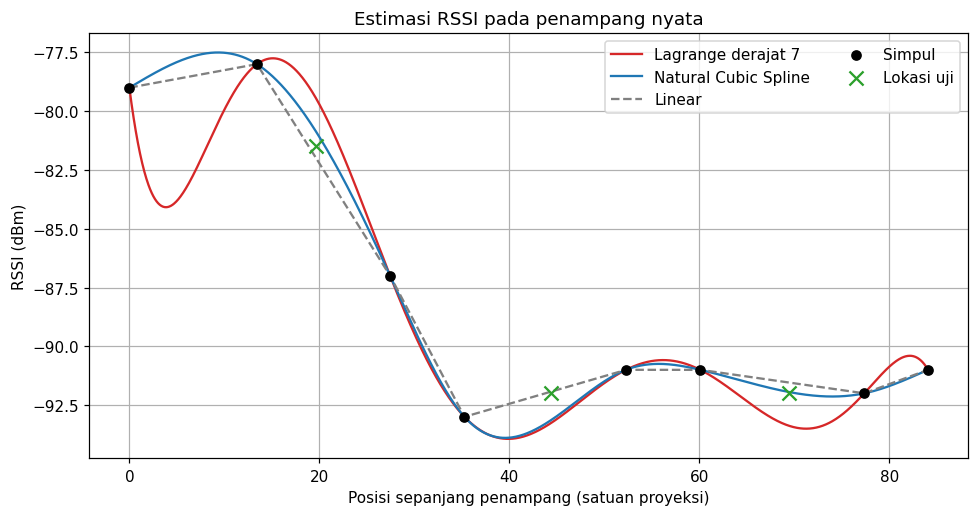

In [8]:
predictions = {
    "Lagrange": lagrange(x, y, x_test),
    "Natural Cubic Spline": spline_eval(x, y, M, x_test),
    "Linear": np.interp(x_test, x, y),
}
estimates = pd.DataFrame({"s": x_test, "RSSI_rujukan": y_test, **predictions})
rows = []
for method, pred in predictions.items():
    error = pred - y_test
    rows.append({"metode": method, "MAE_dB": np.mean(np.abs(error)),
                 "RMSE_dB": np.sqrt(np.mean(error**2)), "maks_galat_dB": np.max(np.abs(error))})
metrics = pd.DataFrame(rows)
print("Estimasi RSSI (dBm):")
print(estimates.round(4).to_string(index=False))
print("\nGalat pada lokasi uji (dB):")
print(metrics.round(4).to_string(index=False))
estimates.to_csv(OUT / "estimasi_uji.csv", index=False)
metrics.to_csv(OUT / "metrik_uji.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(grid, lagrange(x, y, grid), label=f"Lagrange derajat {len(x)-1}", color="tab:red")
ax.plot(grid, spline_eval(x, y, M, grid), label="Natural Cubic Spline", color="tab:blue")
ax.plot(grid, np.interp(grid, x, y), "--", label="Linear", color="0.5")
ax.scatter(x, y, c="black", label="Simpul", zorder=4)
ax.scatter(x_test, y_test, marker="x", s=85, c="tab:green", label="Lokasi uji", zorder=5)
ax.set(xlabel="Posisi sepanjang penampang (satuan proyeksi)", ylabel="RSSI (dBm)", title="Estimasi RSSI pada penampang nyata")
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(OUT / "01_interpolasi_rssi.png", dpi=180)
plt.show()

## 9. Pengaruh jumlah titik acuan
Kita mencoba 4, 6, dan seluruh titik acuan yang tersedia, dengan pilihan titik yang tersebar sepanjang jalur. Lokasi pengujian tetap sama agar hasilnya bisa dibandingkan.

Apakah memakai lebih banyak titik selalu membuat perkiraan lebih akurat? Tabel dan grafik berikut membantu menjawabnya. Perubahan hasil dapat dipengaruhi bentuk sinyal, variasi pembacaan alat, dan posisi titik acuan. Karena itu, naiknya galat pada data RSSI saja belum cukup untuk disebut fenomena Runge.

 simpul  derajat_global               metode  RMSE_dB
      4               3             Lagrange   2.5435
      4               3 Natural Cubic Spline   2.4410
      6               5             Lagrange   1.6066
      6               5 Natural Cubic Spline   0.5349
      8               7             Lagrange   1.5967
      8               7 Natural Cubic Spline   0.7466


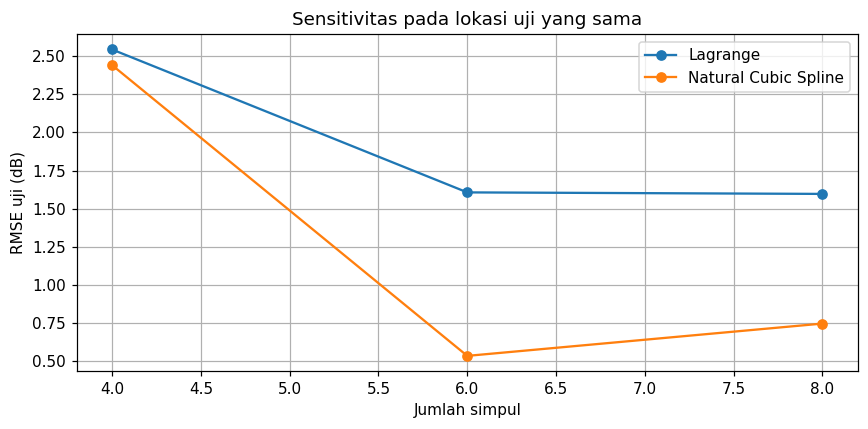

In [9]:
sensitivity_rows = []
for k in sorted(set([4, 6, len(x)])):
    selected = np.unique(np.rint(np.linspace(0, len(x)-1, k)).astype(int))
    xn, yn = x[selected], y[selected]
    for method, pred in {
        "Lagrange": lagrange(xn, yn, x_test),
        "Natural Cubic Spline": spline_eval(xn, yn, spline_coef(xn, yn), x_test)
    }.items():
        sensitivity_rows.append({"simpul": len(xn), "derajat_global": len(xn)-1,
                                 "metode": method, "RMSE_dB": np.sqrt(np.mean((pred-y_test)**2))})
sensitivity = pd.DataFrame(sensitivity_rows)
print(sensitivity.round(4).to_string(index=False))
sensitivity.to_csv(OUT / "sensitivitas_simpul.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4))
for method, g in sensitivity.groupby("metode", sort=False):
    ax.plot(g.simpul, g.RMSE_dB, "o-", label=method)
ax.set(xlabel="Jumlah simpul", ylabel="RMSE uji (dB)", title="Sensitivitas pada lokasi uji yang sama")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "02_sensitivitas.png", dpi=180)
plt.show()

## 10. Mengapa kurva bisa bergelombang saat titiknya ditambah?

Saat jumlah titik acuan bertambah, Lagrange harus membuat satu kurva yang melewati semua titik itu. Kurvanya kadang justru naik-turun berlebihan, terutama dekat ujung rentang. Perilaku ini disebut **fenomena Runge**.

Untuk melihatnya dengan jelas, kita memakai fungsi contoh:
$$f(u)=\frac{1}{1+25u^2},\qquad -1\leq u\leq1.$$
Di sini, $u$ hanya posisi pada sumbu mendatar. Ini bukan data RSSI dan bukan jarak dari pemancar.

Mengapa memakai fungsi contoh? Nilai yang benar di setiap posisi bisa langsung dihitung dari rumus. Jadi, kita bisa memeriksa seberapa jauh hasil interpolasi meleset. Nilainya diambil langsung dari rumus, tanpa tambahan perubahan acak seperti yang dapat terjadi saat alat mengukur sinyal.

Kita membandingkan Lagrange dengan spline menggunakan titik acuan berjarak sama. Lagrange diuji pada derajat 4, 8, 12, 16, dan 20. Derajat yang lebih besar di sini berarti memakai lebih banyak titik acuan. Spline tetap memakai kurva kubik pada setiap bagian di antara dua titik.

Sebagai pembanding tambahan, dipakai titik **Chebyshev–Lobatto**, yaitu titik acuan yang lebih rapat di dekat kedua ujung. Tujuannya untuk melihat apakah mengubah posisi titik dapat mengurangi gelombang berlebihan pada Lagrange.

Selisih terbesar diperiksa pada 4.001 posisi. Angka yang dilaporkan adalah selisih terbesar dari posisi-posisi tersebut, bukan jaminan nilai terbesar di setiap posisi yang mungkin ada.

 derajat               metode  maks_galat_grid
       4     Lagrange seragam         0.438357
       4 Natural Cubic Spline         0.279313
       4   Lagrange Chebyshev         0.459981
       8     Lagrange seragam         1.045174
       8 Natural Cubic Spline         0.056074
       8   Lagrange Chebyshev         0.204682
      12     Lagrange seragam         3.663376
      12 Natural Cubic Spline         0.006909
      12   Lagrange Chebyshev         0.084396
      16     Lagrange seragam        14.393851
      16 Natural Cubic Spline         0.003745
      16   Lagrange Chebyshev         0.036713
      20     Lagrange seragam        59.822309
      20 Natural Cubic Spline         0.003183
      20   Lagrange Chebyshev         0.017738


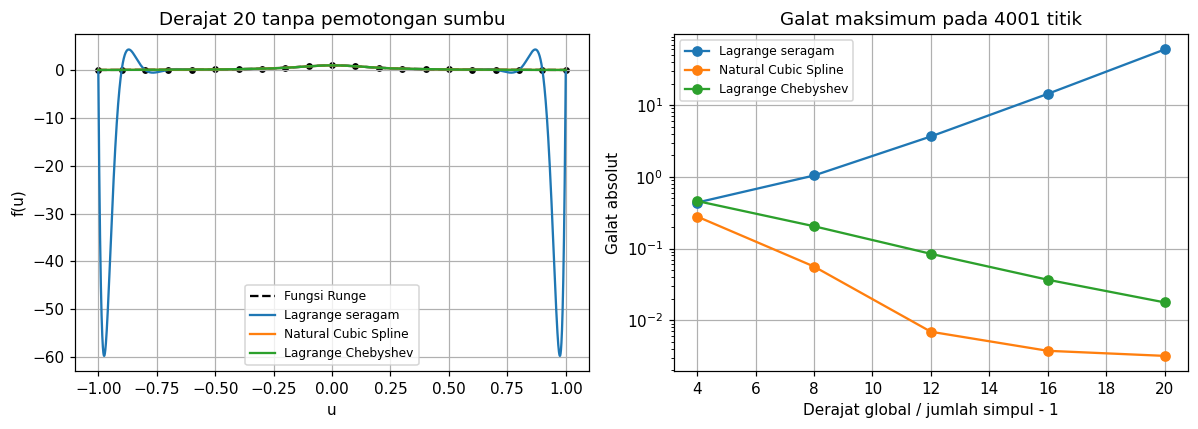

In [10]:
def runge(u):
    return 1 / (1 + 25 * u**2)

u = np.linspace(-1, 1, 4001)
truth = runge(u)
runge_rows = []
for degree in [4, 8, 12, 16, 20]:
    uniform = np.linspace(-1, 1, degree+1)
    cheb = np.sort(np.cos(np.arange(degree+1) * np.pi / degree))
    values = runge(uniform)
    curves = {
        "Lagrange seragam": lagrange(uniform, values, u),
        "Natural Cubic Spline": spline_eval(uniform, values, spline_coef(uniform, values), u),
        "Lagrange Chebyshev": lagrange(cheb, runge(cheb), u),
    }
    # Bandingkan dengan SciPy untuk mengecek perhitungan Lagrange.
    assert np.allclose(curves["Lagrange seragam"], BarycentricInterpolator(uniform, values)(u), atol=1e-7, rtol=1e-8)
    for method, curve in curves.items():
        runge_rows.append({"derajat": degree, "metode": method, "maks_galat_grid": np.max(np.abs(curve-truth))})
runge_metrics = pd.DataFrame(runge_rows)
print(runge_metrics.round(6).to_string(index=False))
runge_metrics.to_csv(OUT / "runge.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(u, truth, "k--", label="Fungsi Runge")
for method, curve in curves.items():
    axes[0].plot(u, curve, label=method)
axes[0].scatter(uniform, values, s=12, c="k")
axes[0].set(title="Derajat 20 tanpa pemotongan sumbu", xlabel="u", ylabel="f(u)")
axes[0].legend(fontsize=8)
for method, g in runge_metrics.groupby("metode", sort=False):
    axes[1].semilogy(g.derajat, g.maks_galat_grid, "o-", label=method)
axes[1].set(title="Galat maksimum pada 4001 titik", xlabel="Derajat global / jumlah simpul - 1", ylabel="Galat absolut")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "03_runge.png", dpi=180)
plt.show()

## 11. Membuat peta kekuatan sinyal
Peta ini memakai median RSSI dari AP yang sama pada semua lokasi yang mendeteksinya di gedung dan lantai terpilih. Untuk peta utama digunakan `LinearNDInterpolator`, interpolasi linear per segitiga yang menjaga hasil perkiraan di dalam rentang nilai titik-titik sudut segitiga. Sebagai pemeriksaan tambahan, dihitung juga rentang `CloughTocher2DInterpolator`, interpolasi kubik potongan 2D yang dapat menghasilkan nilai terlalu tinggi atau terlalu rendah ketika posisi pengukuran berdekatan tetapi nilainya berbeda. **Keduanya bukan natural cubic spline 1D** dan bukan metode Lagrange untuk seluruh titik pada peta. Pemilihan kontur linear tidak mengubah perbandingan utama Lagrange dan spline pada penampang.

Warna peta hanya ditampilkan di dalam area yang dibatasi oleh titik-titik pengukuran paling luar, yang disebut convex hull. Area di luarnya dibiarkan kosong (`NaN`). Dinding, bentuk koridor, dan area yang tidak bisa dilalui tidak diketahui, sehingga warna di antara titik yang jauh tidak menjamin cakupan fisik nyata. Kontur ini memakai semua titik dan tidak dijadikan pengujian galat model 1D.

Rentang nilai (dBm): {'RSSI terukur': [-96.0, -57.0], 'Kontur linear': [-95.98528399046684, -57.35022751124557], 'Kubik 2D diagnostik': [-174.87863106164662, 108.55535644253287]}


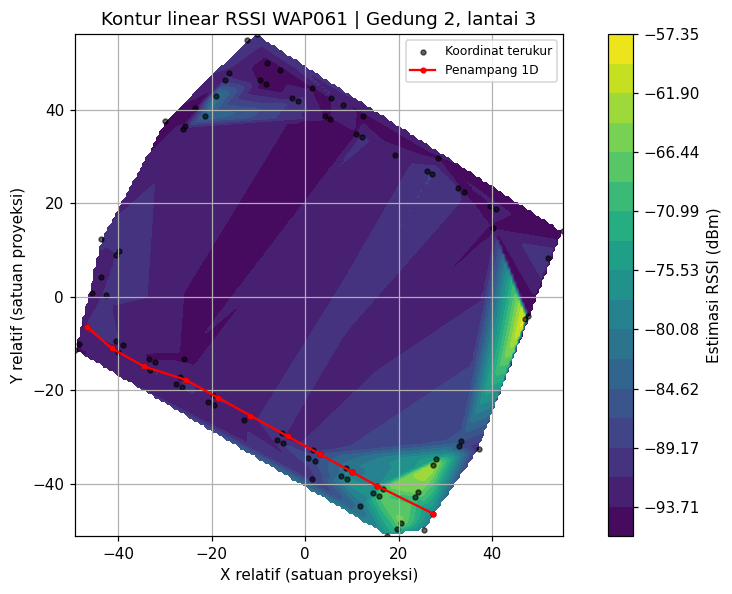

In [11]:
spatial = locations.dropna(subset=[ap]).copy()
coords = spatial[["LONGITUDE", "LATITUDE"]].to_numpy() - origin
values2d = spatial[ap].to_numpy()
gx, gy = np.meshgrid(np.linspace(coords[:,0].min(), coords[:,0].max(), 180),
                     np.linspace(coords[:,1].min(), coords[:,1].max(), 180))
interp2d = LinearNDInterpolator(coords, values2d, fill_value=np.nan)
gz = interp2d(gx, gy)
cubic2d = CloughTocher2DInterpolator(coords, values2d, fill_value=np.nan)(gx, gy)
contour_ranges = {"RSSI terukur": [float(values2d.min()), float(values2d.max())],
                  "Kontur linear": [float(np.nanmin(gz)), float(np.nanmax(gz))],
                  "Kubik 2D diagnostik": [float(np.nanmin(cubic2d)), float(np.nanmax(cubic2d))]}
print("Rentang nilai (dBm):", contour_ranges)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
levels = np.linspace(np.nanmin(gz), np.nanmax(gz), 18)
contour = ax.contourf(gx, gy, np.ma.masked_invalid(gz), levels=levels, cmap="viridis")
ax.scatter(coords[:,0], coords[:,1], s=10, c="black", alpha=0.6, label="Koordinat terukur")
pp = profile[["LONGITUDE", "LATITUDE"]].to_numpy() - origin
ax.plot(pp[:,0], pp[:,1], "r.-", label="Penampang 1D")
ax.set(xlabel="X relatif (satuan proyeksi)", ylabel="Y relatif (satuan proyeksi)",
       title=f"Kontur linear RSSI {ap} | Gedung {building}, lantai {floor}")
ax.set_aspect("equal")
ax.legend(loc="best", fontsize=8)
fig.colorbar(contour, ax=ax, label="Estimasi RSSI (dBm)")
fig.tight_layout()
fig.savefig(OUT / "04_kontur.png", dpi=180)
plt.show()

## 12. Cara membaca hasilnya
- Bandingkan perkiraan dengan pengukuran pada lokasi uji. Kurva yang melewati semua titik acuan belum tentu akurat di antara titik-titik itu.
- Lagrange memakai satu kurva untuk seluruh titik. Spline menyambungkan beberapa kurva kubik yang masing-masing mengisi bagian di antara dua titik.
- Contoh fungsi Runge menunjukkan bahwa menambah titik berjarak sama dapat membuat Lagrange bergelombang berlebihan di dekat ujung. Pada data RSSI, pembacaan alat juga bisa berubah-ubah, sehingga penyebab perbedaannya tidak persis sama.
- Hasil untuk satu access point dan satu jalur belum tentu berlaku untuk seluruh jaringan. Spline juga bisa meleset atau menghasilkan nilai di luar rentang titik acuan. Pada beberapa kasus, interpolasi linear justru lebih akurat.
- Kita hanya memperkirakan nilai di antara titik paling kiri dan paling kanan. Syarat batas natural pada spline adalah pilihan perhitungan, bukan aturan fisika sinyal Wi-Fi.

In [12]:
best_method = metrics.sort_values("RMSE_dB").iloc[0]
summary = {
    "building": building, "floor": floor, "ap": ap, "rows_floor": len(subset),
    "unique_locations_floor": len(locations), "spatial_locations": len(spatial),
    "angle": angle, "strip_center": center, "strip_points": best_count,
    "profile_points": len(profile), "train_points": len(train), "test_points": len(test),
    "span": float(profile.s.max()), "max_offset": float(profile.offset.abs().max()),
    "source_sha256": source_hash, "verification": verification, "contour_ranges": contour_ranges,
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__},
    "metrics": metrics.to_dict(orient="records"),
}
(OUT / "ringkasan.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(f"RMSE terendah pada uji ini: {best_method.metode} = {best_method.RMSE_dB:.4f} dB")
print("Simpan kesimpulan sesuai angka aktual, bukan asumsi bahwa spline selalu menang.")
print("Tabel, gambar, dan metadata eksekusi tersimpan pada folder hasil.")

RMSE terendah pada uji ini: Linear = 0.3921 dB
Simpan kesimpulan sesuai angka aktual, bukan asumsi bahwa spline selalu menang.
Tabel, gambar, dan metadata eksekusi tersimpan pada folder hasil.


## Referensi
1. Torres-Sospedra, J. dkk. (2014). UJIIndoorLoc. UCI Machine Learning Repository. https://doi.org/10.24432/C5MS59. CC BY 4.0.
2. Salinan Kaggle: https://www.kaggle.com/datasets/giantuji/UjiIndoorLoc.
3. SciPy. CubicSpline. https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html.
4. SciPy. BarycentricInterpolator. https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.BarycentricInterpolator.html.
5. SciPy. CloughTocher2DInterpolator. https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CloughTocher2DInterpolator.html.
6. SciPy. LinearNDInterpolator. https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.LinearNDInterpolator.html.
7. Improving Indoor WiFi Localization by Using Machine Learning Techniques (2024). https://pmc.ncbi.nlm.nih.gov/articles/PMC11478429/. Rujukan sistem koordinat proyeksi dataset.